In [2]:
from pathlib import Path
import math
import os
import random
from joblib import Parallel, delayed

import torch
from torch.utils.data import DataLoader
from torch import optim
from torch.nn.functional import l1_loss
from braindecode.preprocessing import create_fixed_length_windows
from braindecode.datasets.base import EEGWindowsDataset, BaseConcatDataset, BaseDataset
from braindecode.models import EEGNeX
from eegdash import EEGChallengeDataset

# Data reading

In [10]:
DATA_DIR = Path("D:\Work_data\EEG_challenge")
# The first step is define the cache folder!


# We define the list of releases to load.
# Here, only release 5 is loaded.
release_list = ["R11","R10"] #R6 -> ds005510-bdf ; R3->ds005507-bdf; R7 ->ds005511-bdf
#R1 -> ds005505-bdf ; R4 -> ds005508-bdf ; R2 -> ds005506-bdf; R8 -> ds005512-bdf
# R9 -> ds005514-bdf; R10 ->ds005515-bdf ; R11 -> ds005516-bdf
task = ["contrastChangeDetection","RestingState"]
all_datasets_list = [EEGChallengeDataset(release=release,task=task,mini=False,download= False,
                                         description_fields=["subject","session","run","task","age","gender","sex","p_factor",],cache_dir=DATA_DIR,)
                    for release in release_list]
print("Datasets loaded")


c:\Users\Prakash\anaconda3\envs\eegneuronets\lib\site-packages\eegdash\dataset\dataset.py:126: UserWarning: 

[EEGChallengeDataset] EEG 2025 Competition Data Notice:
-------------------------------------------------------
This object loads the HBN dataset that has been preprocessed for the EEG Challenge:
  - Downsampled from 500Hz to 100Hz
  - Bandpass filtered (0.5–50 Hz)

For full preprocessing details, see:
  https://github.com/eeg2025/downsample-datasets

IMPORTANT: The data accessed via `EEGChallengeDataset` is NOT identical to what you get from `EEGDashDataset` directly.
If you are participating in the competition, always use `EEGChallengeDataset` to ensure consistency with the challenge data.


  warn(


KeyboardInterrupt: 

In [6]:
# combine the dataset 
all_datasets = BaseConcatDataset(all_datasets_list)
print(all_datasets.description)

          subject                     task      age sex  p_factor  \
0    NDARAB055BPR             RestingState  10.7939   F     0.366   
1    NDARAB055BPR  contrastChangeDetection  10.7939   F     0.366   
2    NDARAB055BPR  contrastChangeDetection  10.7939   F     0.366   
3    NDARAB055BPR  contrastChangeDetection  10.7939   F     0.366   
4    NDARAB348EWR             RestingState   5.8054   M     0.854   
..            ...                      ...      ...  ..       ...   
362  NDARZR538EZH  contrastChangeDetection  21.0009   F       NaN   
363  NDARZR538EZH  contrastChangeDetection  21.0009   F       NaN   
364  NDARZY224TFX             RestingState   6.7916   M    -1.045   
365  NDARZY224TFX  contrastChangeDetection   6.7916   M    -1.045   
366  NDARZY224TFX  contrastChangeDetection   6.7916   M    -1.045   

    release_number  ehq_total commercial_use full_pheno  attention  ...  \
0               R6      60.03            Yes        Yes      1.029  ...   
1               R6   

<Info | 9 non-empty values
 bads: []
 ch_names: E1, E2, E3, E4, E5, E6, E7, E8, E9, E10, E11, E12, E13, E14, ...
 chs: 129 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 line_freq: 60.0
 lowpass: 50.0 Hz
 meas_date: 2025-08-19 14:40:00 UTC
 nchan: 129
 projs: []
 sfreq: 100.0 Hz
 subject_info: <subject_info | his_id: sub-NDARAB055BPR, sex: 2, birthday: 2014-11-02>
>
Using matplotlib as 2D backend.


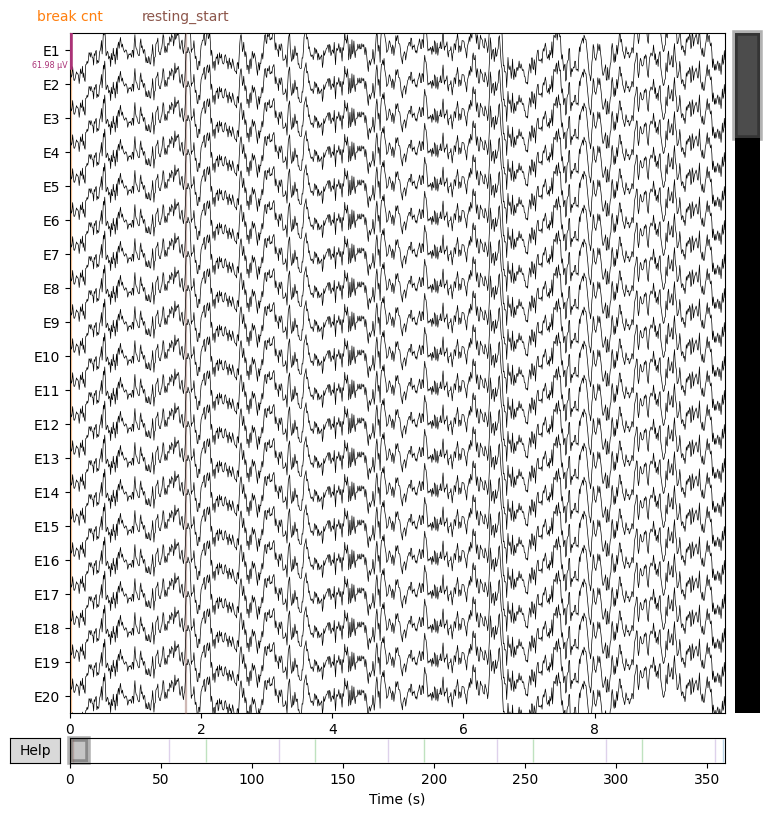

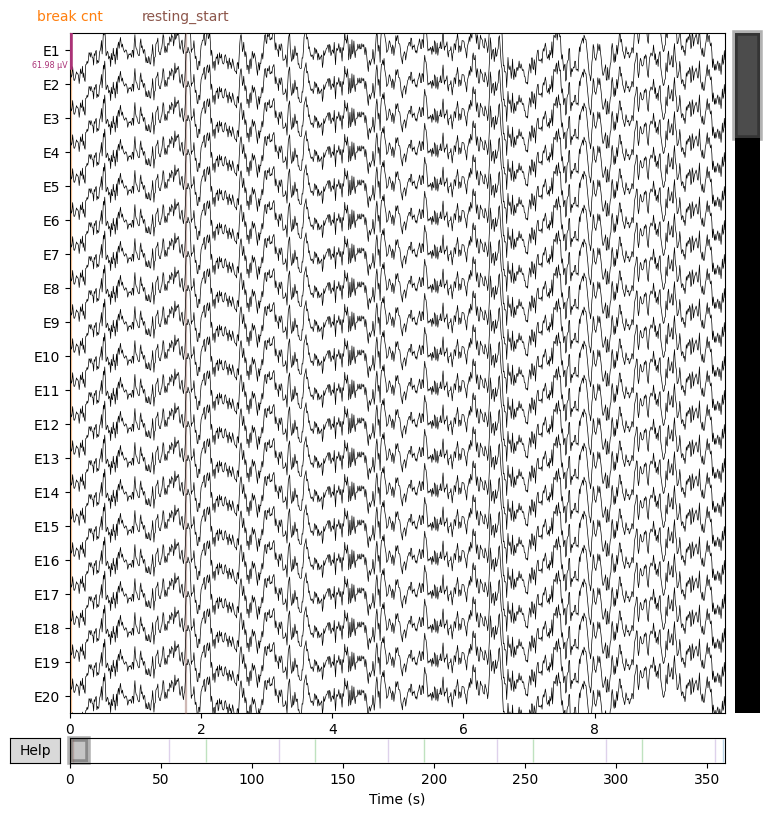

In [7]:
raws = Parallel(n_jobs=os.cpu_count())(
    delayed(lambda d: d.raw)(d) for d in all_datasets.datasets
)
raw = all_datasets.datasets[0].raw  # mne.io.Raw object
print(raw.info)

raw.plot(duration=10, scalings="auto", show=True)


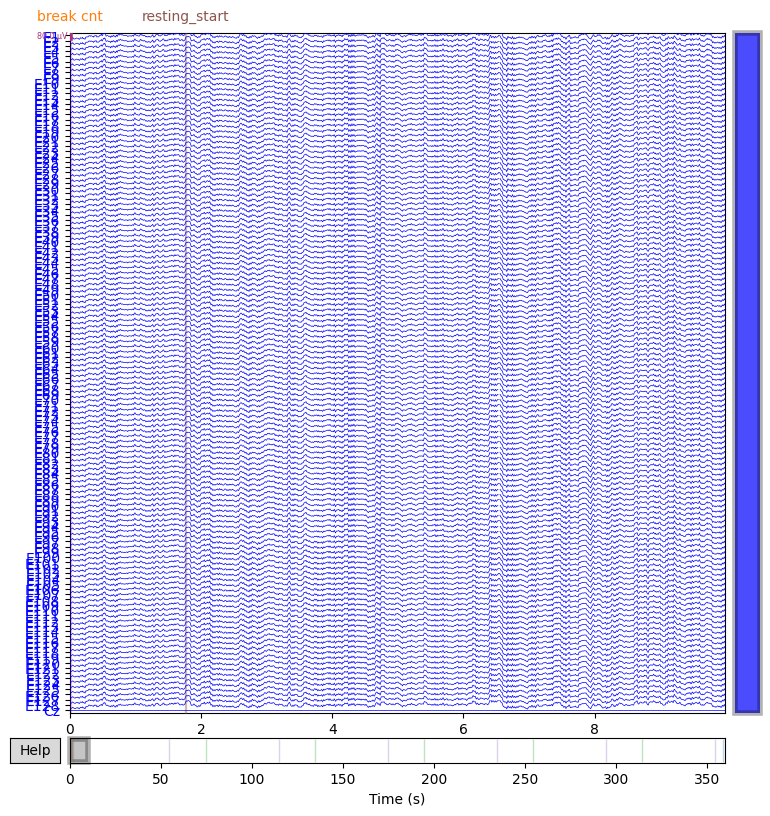

Channels marked as bad:
none


In [12]:
%matplotlib qt
raw.plot(scalings=dict(eeg=40e-6),clipping='transparent', n_channels=129,color = "Blue",event_color ='black',show_options=True )

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 20.480 (s)
Plotting power spectral density (dB=True).


C:\Users\Prakash\AppData\Local\Temp\ipykernel_16376\546364069.py:1: UserWarning: Zero value in spectrum for channel Cz
  raw.plot_psd( fmax=50,)
C:\Users\Prakash\AppData\Local\Temp\ipykernel_16376\546364069.py:1: UserWarning: Infinite value in PSD for channel Cz.
These channels might be dead.
  raw.plot_psd( fmax=50,)
C:\Users\Prakash\AppData\Local\Temp\ipykernel_16376\546364069.py:1: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw.plot_psd( fmax=50,)


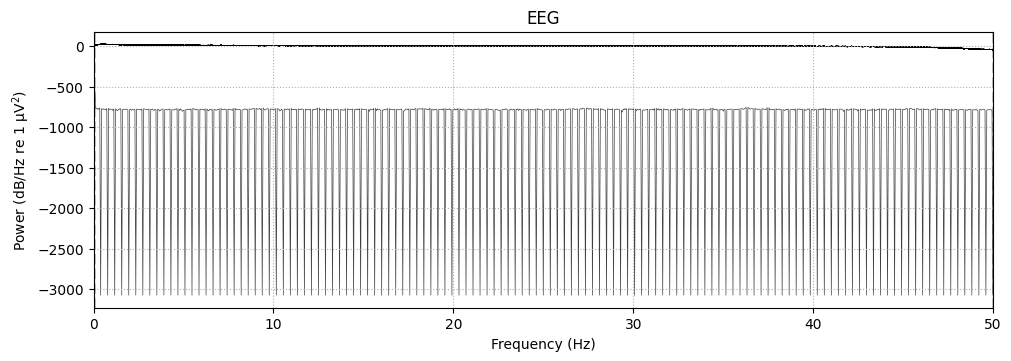

In [26]:
raw.plot_psd( fmax=50,)

In [4]:
class DatasetWrapper(BaseDataset):
    def __init__(self, dataset: EEGWindowsDataset, crop_size_samples: int, seed=None):
        self.dataset = dataset
        self.crop_size_samples = crop_size_samples
        self.rng = random.Random(seed)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        X, _, crop_inds = self.dataset[index]

        # P-factor label:
        p_factor = self.dataset.description["p_factor"]
        p_factor = float(p_factor)

        # Additional information:
        infos = {
            "subject": self.dataset.description["subject"],
            "sex": self.dataset.description["sex"],
            "age": float(self.dataset.description["age"]),
            "task": self.dataset.description["task"],
            "session": self.dataset.description.get("session", None) or "",
            "run": self.dataset.description.get("run", None) or "",
        }

        # # Randomly crop the signal to the desired length:
        i_window_in_trial, i_start, i_stop = crop_inds
        # assert i_stop - i_start >= self.crop_size_samples, f"{i_stop=} {i_start=}"
        # start_offset = self.rng.randint(0, i_stop - i_start - self.crop_size_samples)
        # i_start = i_start + start_offset
        # i_stop = i_start + self.crop_size_samples
        # X = X[:, start_offset : start_offset + self.crop_size_samples]

        return X, p_factor, (i_window_in_trial, i_start, i_stop), infos

In [5]:
SFREQ = 100
sub_rm = ["NDARWV769JM7", "NDARME789TD2", "NDARUA442ZVF", "NDARJP304NK1",
          "NDARTY128YLU", "NDARDW550GU6", "NDARLD243KRE", "NDARUJ292JXV", "NDARBA381JGH"]
# Filter out recordings that are too short
all_datasets = BaseConcatDataset(
    [
        ds
        for ds in all_datasets.datasets
        if not ds.description.subject in sub_rm   # remove the subject is not relevent
        and ds.raw.n_times >= 4 * SFREQ ## take subject with recording more the 4*100
        and len(ds.raw.ch_names) == 129 ## nuber of channel shoud be 129 
        and not math.isnan(ds.description["p_factor"])  ## p factor is not null
    ]
)

# Create 4-seconds windows with 2-seconds stride
windows_ds = create_fixed_length_windows(
    all_datasets,
    window_size_samples=2 * SFREQ,
    window_stride_samples=50,
    drop_last_window=True,
)

# Wrap each sub-dataset in the windows_ds
windows_ds = BaseConcatDataset(
    [DatasetWrapper(ds, crop_size_samples=2 * SFREQ) for ds in windows_ds.datasets]
)

In [6]:
len(windows_ds)
233066/1024

227.603515625

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    msg = "CUDA-enabled GPU found. Training should be faster."
else:
    msg = (
        "No GPU found. Training will be carried out on CPU, which might be "
        "slower.\n\nIf running on Google Colab, you can request a GPU runtime by"
        " clicking\n`Runtime/Change runtime type` in the top bar menu, then "
        "selecting 'T4 GPU'\nunder 'Hardware accelerator'."
    )
print(msg)

CUDA-enabled GPU found. Training should be faster.


In [8]:
# Initialize model
model = EEGNeX(n_chans=129, n_outputs=1, n_times=2 * SFREQ).to(device)

# Specify optimizer
optimizer = optim.Adamax(params=model.parameters(), lr=0.002)

print(model)

Layer (type (var_name):depth-idx)                            Input Shape               Output Shape              Param #                   Kernel Shape
EEGNeX (EEGNeX)                                              [1, 129, 200]             [1, 1]                    --                        --
├─Sequential (block_1): 1-1                                  [1, 129, 200]             [1, 8, 129, 200]          --                        --
│    └─Rearrange (0): 2-1                                    [1, 129, 200]             [1, 1, 129, 200]          --                        --
│    └─Conv2d (1): 2-2                                       [1, 1, 129, 200]          [1, 8, 129, 200]          512                       [1, 64]
│    └─BatchNorm2d (2): 2-3                                  [1, 8, 129, 200]          [1, 8, 129, 200]          16                        --
├─Sequential (block_2): 1-2                                  [1, 8, 129, 200]          [1, 32, 129, 200]         --                  

c:\Users\PRAKASH\AppData\Local\anaconda3\envs\eegneuronets\lib\site-packages\torch\nn\modules\conv.py:549: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\Convolution.cpp:1037.)
  return F.conv2d(


In [9]:
# Create PyTorch Dataloader
num_workers = 0 # We are using a single worker, but you can increase this for faster data loading

dataloader = DataLoader(windows_ds, batch_size=1024, shuffle=True, num_workers=num_workers)

n_epochs = 50

# Train model for 1 epoch
for epoch in range(n_epochs):
    print('epoch strated ', epoch)

    for idx, batch in enumerate(dataloader):
        # Reset gradients
        optimizer.zero_grad()

        # Unpack the batch
        X, y, crop_inds, infos = batch
        X = X.to(dtype=torch.float32, device=device)
        y = y.to(dtype=torch.float32, device=device).unsqueeze(1)

        # Forward pass
        y_pred = model(X)

        # Compute loss
        loss = l1_loss(y_pred, y)
        print(f"Epoch {epoch} - step {idx}, loss: {loss.item()}")

        # Gradient backpropagation
        loss.backward()
        optimizer.step()
    print(f"Epoch {epoch } - step {idx}, loss: {loss.item()}")
# Finally, we can save the model for later use
torch.save(model.state_dict(), "model_weights_challenge_2.pt") 

epoch strated  0
Epoch 0 - step 0, loss: 0.7124177813529968
Epoch 0 - step 1, loss: 0.7276305556297302
Epoch 0 - step 2, loss: 0.7203599810600281
Epoch 0 - step 3, loss: 0.7028754353523254
Epoch 0 - step 4, loss: 0.6881717443466187
Epoch 0 - step 5, loss: 0.7277766466140747
Epoch 0 - step 6, loss: 0.6820133328437805
Epoch 0 - step 7, loss: 0.7182555794715881
Epoch 0 - step 8, loss: 0.6710419654846191
Epoch 0 - step 9, loss: 0.7206224799156189
Epoch 0 - step 10, loss: 0.7213923931121826
Epoch 0 - step 11, loss: 0.6954172849655151
Epoch 0 - step 12, loss: 0.6739230155944824
Epoch 0 - step 13, loss: 0.6826865673065186
Epoch 0 - step 14, loss: 0.69133460521698
Epoch 0 - step 15, loss: 0.7107141017913818
Epoch 0 - step 16, loss: 0.6788796186447144
Epoch 0 - step 17, loss: 0.7018632888793945
Epoch 0 - step 18, loss: 0.6703238487243652
Epoch 0 - step 19, loss: 0.6848612427711487
Epoch 0 - step 20, loss: 0.704636812210083
Epoch 0 - step 21, loss: 0.6731500029563904
Epoch 0 - step 22, loss: 0.6